# Implementasi Graf Berarah, Tidak Berarah, dan Analisis Metrik

Dokumen ini memuat implementasi **Graf Tidak Berarah (Undirected Graph)** dan **Graf Berarah (Directed Graph)** menggunakan pustaka Python `networkx` dan `matplotlib`, beserta analisis metrik dasarnya.

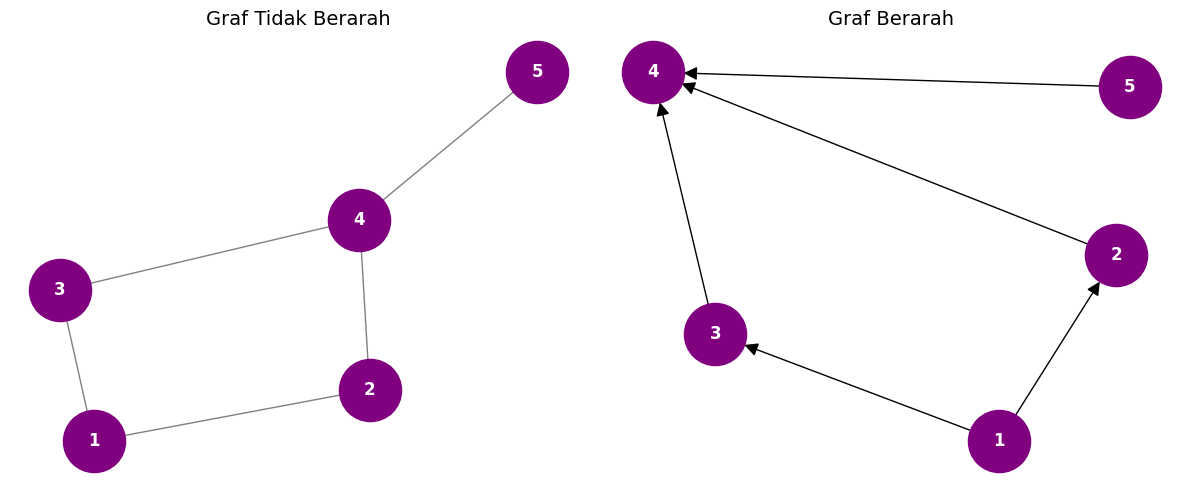

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import collections

# ==========================================
# 1. Pembuatan Graf
# ==========================================
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

# --- Graf Tidak Berarah ---
G_undirected = nx.Graph()
edges_undirected = [(1, 2), (1, 3), (2, 4), (3, 4), (4, 5)]
G_undirected.add_edges_from(edges_undirected)
pos_undirected = nx.spring_layout(G_undirected, seed=42)

axes[0].set_title("Graf Tidak Berarah", fontsize=14)
nx.draw(G_undirected, pos_undirected, ax=axes[0],
        with_labels=True, node_color='purple',
        node_size=2000, font_size=12, font_weight='bold',
        font_color='white', edge_color='gray')

# --- Graf Berarah ---
G_directed = nx.DiGraph()
edges_directed = [(1, 2), (1, 3), (2, 4), (3, 4), (5, 4)]
G_directed.add_edges_from(edges_directed)
pos_directed = nx.spring_layout(G_directed, seed=42)

axes[1].set_title("Graf Berarah", fontsize=14)
nx.draw(G_directed, pos_directed, ax=axes[1],
        with_labels=True, node_color='purple',
        node_size=2000, font_size=12, font_weight='bold',
        font_color='white', edge_color='black',
        arrows=True, arrowsize=20)

plt.tight_layout()
plt.show()

## 2. Metrik Dasar Graf (Pada Graf Tidak Berarah)
Bagian ini akan menghitung derajat, rata-rata derajat, kepadatan, dan matriks ketetanggaan dari `G_undirected`.

In [3]:
# A. Menghitung Derajat (Degree)
degrees = dict(G_undirected.degree())
print("--- Derajat (Degree) masing-masing simpul ---")
for node, deg in sorted(degrees.items()):
    print(f"Simpul {node}: {deg} sisi")

# B. Menghitung Rata-rata Derajat
avg_degree = sum(degrees.values()) / G_undirected.number_of_nodes()
print(f"\nRata-rata Derajat: {avg_degree}")

# C. Menghitung Kepadatan (Density)
density = nx.density(G_undirected)
print(f"\nKepadatan (Density) Graf: {density:.3f}")

# D. Menampilkan Matriks Ketetanggaan (Adjacency Matrix)
adj_matrix = nx.adjacency_matrix(G_undirected).todense()
print("\n--- Matriks Ketetanggaan (Adjacency Matrix) ---")
print(adj_matrix)

--- Derajat (Degree) masing-masing simpul ---
Simpul 1: 2 sisi
Simpul 2: 2 sisi
Simpul 3: 2 sisi
Simpul 4: 3 sisi
Simpul 5: 1 sisi

Rata-rata Derajat: 2.0

Kepadatan (Density) Graf: 0.500

--- Matriks Ketetanggaan (Adjacency Matrix) ---
[[0 1 1 0 0]
 [1 0 0 1 0]
 [1 0 0 1 0]
 [0 1 1 0 1]
 [0 0 0 1 0]]


### Visualisasi Distribusi Derajat
Distribusi derajat menunjukkan frekuensi munculnya setiap nilai derajat di dalam graf menggunakan *bar chart*.

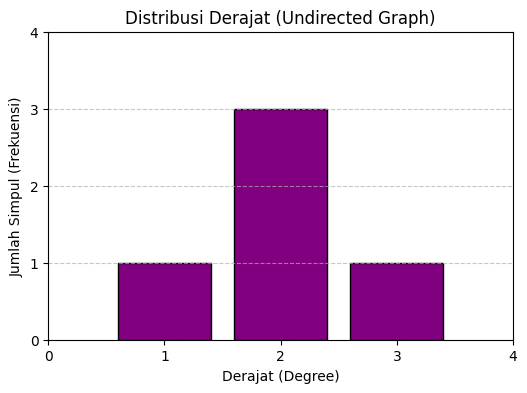

In [2]:
# Mengambil nilai derajat dan menghitung frekuensinya
degree_sequence = sorted([d for n, d in G_undirected.degree()], reverse=True)
degree_count = collections.Counter(degree_sequence)
deg, cnt = zip(*degree_count.items())

# Membuat visualisasi bar chart
plt.figure(figsize=(6, 4))
plt.bar(deg, cnt, width=0.80, color="purple", edgecolor="black")

plt.title("Distribusi Derajat (Undirected Graph)")
plt.ylabel("Jumlah Simpul (Frekuensi)")
plt.xlabel("Derajat (Degree)")
plt.xticks(range(max(degree_sequence) + 2))
plt.yticks(range(max(cnt) + 2))
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

### E. Koefisien Klasterisasi (Clustering Coefficient)
Koefisien klasterisasi mengukur seberapa besar kecenderungan simpul-simpul dalam jaringan untuk saling berkelompok membentuk segitiga (komunitas). Nilainya berada di antara **0 hingga 1**.

*   **Koefisien Klasterisasi Lokal:** Mengukur kecenderungan pengelompokan pada satu simpul tertentu (seberapa banyak tetangga dari simpul tersebut yang juga saling terhubung).
*   **Rata-rata Koefisien Klasterisasi (Global):** Merupakan rata-rata dari nilai klasterisasi lokal semua simpul, yang menunjukkan tingkat pengelompokan graf secara keseluruhan.

In [4]:
# 1. Menghitung Koefisien Klasterisasi Lokal untuk setiap simpul
local_clustering = nx.clustering(G_undirected)
print("--- Koefisien Klasterisasi Lokal ---")
for node, cc in sorted(local_clustering.items()):
    print(f"Simpul {node}: {cc:.3f}")

# 2. Menghitung Rata-rata Koefisien Klasterisasi untuk seluruh graf
avg_clustering = nx.average_clustering(G_undirected)
print(f"\nRata-rata Koefisien Klasterisasi (Global): {avg_clustering:.3f}")

--- Koefisien Klasterisasi Lokal ---
Simpul 1: 0.000
Simpul 2: 0.000
Simpul 3: 0.000
Simpul 4: 0.000
Simpul 5: 0.000

Rata-rata Koefisien Klasterisasi (Global): 0.000
